# Chapter 6: Logistic regression

**Note:** This is the new version of the code, using scikit-learn instead of Turi Create (which was deprecated).
If you wish to see the original code in Turi Create that appears in the first edition of the book, please check [here](https://github.com/luisguiserrano/manning/blob/master/Chapter_06_Logistic_Regression/DEPRECATED_Coding_logistic_regression.ipynb).

### Importing packages

In [1]:
import numpy as np
import random
from matplotlib import pyplot as plt

### Plotting functions

In [2]:
def plot_points(features, labels, zoom=None, size=100):
    X = np.array(features)
    y = np.array(labels)
    happy = X[y == 1]
    sad = X[y == 0]
    plt.scatter(happy[:, 0], happy[:, 1], s=size, color='cyan',
                edgecolor='k', marker='^', label='happy', zorder=3)
    plt.scatter(sad[:, 0], sad[:, 1], s=size, color='red',
                edgecolor='k', marker='s', label='sad', zorder=3)
    plt.xlabel('aack')
    plt.ylabel('beep')
    plt.legend(loc='upper right')
    if zoom is not None:
        cx = (X[:, 0].min() + X[:, 0].max()) / 2
        cy = (X[:, 1].min() + X[:, 1].max()) / 2
        r = zoom * max(X[:, 0].max() - X[:, 0].min(), X[:, 1].max() - X[:, 1].min()) / 2
        plt.xlim(cx - r, cx + r)
        plt.ylim(cy - r, cy + r)
        plt.gca().set_aspect('equal')

def draw_line(a, b, c, starting=-10, ending=10, **kwargs):
    # Plots the line a*x + b*y + c = 0
    if b == 0:
        plt.axvline(-c/a, **kwargs)
    else:
        x = np.linspace(starting, ending, 1000)
        plt.plot(x, -c/b - a*x/b, **kwargs)

def plot_boundary(features, labels, coefficients, intercept):
    draw_line(coefficients[0], coefficients[1], intercept,
              color='green', linewidth=2, label='Decision boundary')
    plot_points(features, labels, zoom=3, size=50)
    plt.title('Logistic regression decision boundary')
    plt.show()

### Defining and plotting our dataset (table 6.9)

In [3]:
features = np.array([[1,0],[0,2],[1,1],[1,2],[1,3],[2,2],[2,3],[3,2]])
labels = np.array([0,0,0,0,1,1,1,1])

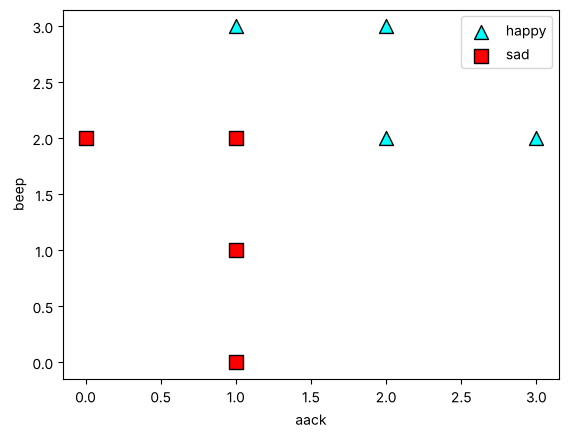

In [4]:
# Plotting the points (figure 6.8)
plot_points(features, labels)
plt.show()

### Logistic regression

In [5]:
def sigmoid(x):
    # Same as 1/(1+np.exp(-x)), the formula in the book
    return np.exp(x)/(1+np.exp(x))

def score(weights, bias, features):
    return np.dot(weights, features) + bias

def prediction(weights, bias, features):
    return sigmoid(score(weights, bias, features))

def log_loss(weights, bias, features, label):
    pred = prediction(weights, bias, features)
    return -label*np.log(pred) - (1-label)*np.log(1-pred)

def total_log_loss(weights, bias, features, labels):
    total_error = 0
    for i in range(len(features)):
        total_error += log_loss(weights, bias, features[i], labels[i])
    return total_error

### Worked examples from the chapter

In [6]:
# Table 6.1: some values of the sigmoid function
for x in [-5, -1, 0, 1, 5]:
    print(x, round(float(sigmoid(x)), 3))
# Expected: -5 0.007, -1 0.269, 0 0.5, 1 0.731, 5 0.993

-5 0.007
-1 0.269
0 0.5
1 0.731
5 0.993


In [7]:
# Tables 6.3 to 6.6: the four sentences of table 6.2, and two classifiers
small_features = np.array([[3,2],[1,2],[0,1],[2,0]])
small_labels = np.array([0,1,1,0])
classifier_1 = ([1, 2], -4)
classifier_2 = ([-1, 1], 0)
for name, (w, b) in [('Classifier 1', classifier_1), ('Classifier 2', classifier_2)]:
    print(name)
    for x, y in zip(small_features, small_labels):
        print('  point', x, 'label', y,
              'prediction', round(float(prediction(w, b, x)), 3),
              'log loss', round(float(log_loss(w, b, x, y)), 3))
    print('  total log loss', round(float(total_log_loss(w, b, small_features, small_labels)), 3))
# Expected:
# Classifier 1: predictions 0.953, 0.731, 0.119, 0.119; log losses 3.049, 0.313, 2.127, 0.127; total 5.616
# Classifier 2: predictions 0.269, 0.731, 0.731, 0.119; log losses 0.313, 0.313, 0.313, 0.127; total 1.067

Classifier 1
  point [3 2] label 0 prediction 0.953 log loss 3.049
  point [1 2] label 1 prediction 0.731 log loss 0.313
  point [0 1] label 1 prediction 0.119 log loss 2.127
  point [2 0] label 0 prediction 0.119 log loss 0.127
  total log loss 5.616
Classifier 2
  point [3 2] label 0 prediction 0.269 log loss 0.313
  point [1 2] label 1 prediction 0.731 log loss 0.313
  point [0 1] label 1 prediction 0.731 log loss 0.313
  point [2 0] label 0 prediction 0.119 log loss 0.127
  total log loss 1.067


In [8]:
def logistic_trick(weights, bias, features, label, learning_rate = 0.05):
    pred = prediction(weights, bias, features)
    for i in range(len(weights)):
        weights[i] += (label-pred)*features[i]*learning_rate
    bias += (label-pred)*learning_rate
    return weights, bias

In [9]:
# Table 6.8: the logistic trick applied to each of the four points, with h = 0.05
for x, y in zip(small_features, small_labels):
    w, b = [1.0, 2.0], -4.0
    before = log_loss(w, b, x, y)
    w, b = logistic_trick(w, b, x, y, learning_rate=0.05)
    print('point', x, 'new weights', [round(float(v), 3) for v in w], 'new bias', round(float(b), 3),
          'new prediction', round(float(prediction(w, b, x)), 3),
          'log loss', round(float(before), 3), '->', round(float(log_loss(w, b, x, y)), 3))
# Expected:
# (3,2): 0.857, 1.905, -4.048, prediction 0.912, log loss 3.049 -> 2.426
# (1,2): 1.013, 2.027, -3.987, prediction 0.747, log loss 0.313 -> 0.292
# (0,1): 1.0, 2.044, -3.956, prediction 0.129, log loss 2.127 -> 2.05
# (2,0): 0.988, 2.0, -4.006, prediction 0.116, log loss 0.127 -> 0.123

point [3 2] new weights [0.857, 1.905] new bias -4.048 new prediction 0.912 log loss 3.049 -> 2.426
point [1 2] new weights [1.013, 2.027] new bias -3.987 new prediction 0.747 log loss 0.313 -> 0.292
point [0 1] new weights [1.0, 2.044] new bias -3.956 new prediction 0.129 log loss 2.127 -> 2.05
point [2 0] new weights [0.988, 2.0] new bias -4.006 new prediction 0.116 log loss 0.127 -> 0.123


### The logistic regression algorithm

In [10]:
def logistic_regression_algorithm(features, labels, learning_rate = 0.05, epochs = 10000):
    weights = [1.0 for i in range(len(features[0]))]
    bias = 0.0
    errors = []
    for i in range(epochs):
        errors.append(total_log_loss(weights, bias, features, labels))
        j = random.randint(0, len(features)-1)
        weights, bias = logistic_trick(weights, bias, features[j], labels[j], learning_rate)
    return weights, bias, errors

In [11]:
random.seed(0)
weights, bias, errors = logistic_regression_algorithm(features, labels)
print('w1 =', round(float(weights[0]), 2))
print('w2 =', round(float(weights[1]), 2))
print('b =', round(float(bias), 2))

w1 = 3.78
w2 = 3.01
b = -11.01


#### Plotting the classifiers during training, and the error (figure 6.9)
The logistic trick changes the classifier at every epoch, so we draw the classifier every 100 epochs.

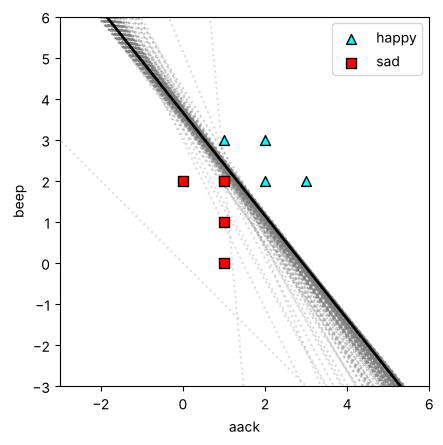

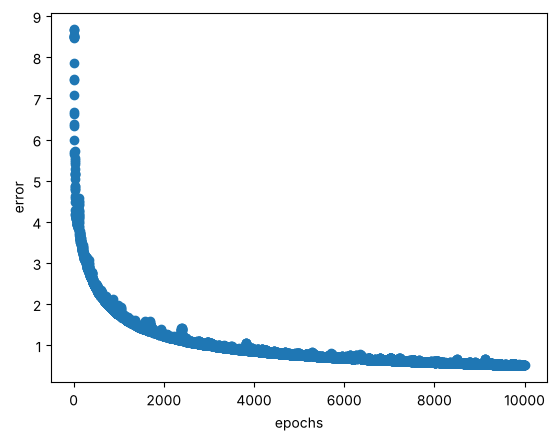

In [12]:
def logistic_regression_with_lines(features, labels, learning_rate = 0.05, epochs = 10000, every = 100):
    # Same as logistic_regression_algorithm, but also stores the classifier every few epochs
    weights = [1.0 for i in range(len(features[0]))]
    bias = 0.0
    lines = []
    for i in range(epochs):
        if i % every == 0:
            lines.append((weights[0], weights[1], bias))
        j = random.randint(0, len(features)-1)
        weights, bias = logistic_trick(weights, bias, features[j], labels[j], learning_rate)
    return lines

random.seed(0)
lines = logistic_regression_with_lines(features, labels)
for k, (a, b, c) in enumerate(lines):
    draw_line(a, b, c, color='gray', linestyle='dotted', alpha=0.25 + 0.6*k/len(lines))
draw_line(weights[0], weights[1], bias, color='black', linewidth=2)
plot_points(features, labels, zoom=3, size=50)
plt.show()

plt.scatter(range(len(errors)), errors)
plt.xlabel('epochs')
plt.ylabel('error')
plt.show()

# Logistic regression using scikit-learn

In [13]:
from sklearn.linear_model import LogisticRegression

In [14]:
logistic_regression = LogisticRegression()
logistic_regression.fit(features, labels)
print("Predictions:", logistic_regression.predict(features))

Predictions: [0 0 0 0 1 1 1 1]


In [15]:
coefficients = logistic_regression.coef_[0]
intercept = logistic_regression.intercept_[0]
print("Weight of aack:", round(float(coefficients[0]), 2))
print("Weight of beep:", round(float(coefficients[1]), 2))
print("Bias:", round(float(intercept), 2))

Weight of aack: 1.0
Weight of beep: 0.94
Bias: -3.16


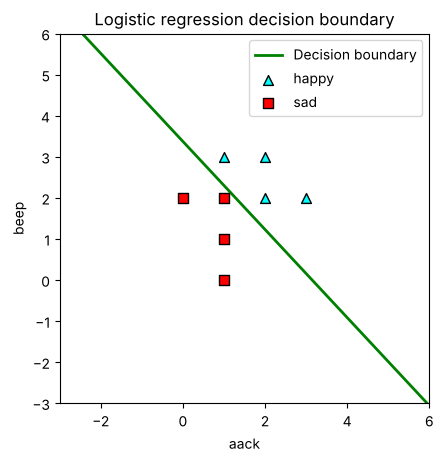

In [16]:
plot_boundary(features, labels, coefficients, intercept)

### The softmax example from the chapter

In [17]:
def softmax(scores):
    exps = np.exp(scores)
    return exps/np.sum(exps)

print([round(float(p), 3) for p in softmax(np.array([3, 2, -1]))])
# Expected: [0.721, 0.265, 0.013]

[0.721, 0.265, 0.013]
